# SWE202 Integrated Practical Assignment
## Design, Implement and Evaluate a University Student Management System

**Module:** Software Architecture & Design  
**Institution:** Bindura University of Science Education  
**Prototype:** Educational Python application using in-memory storage

All records and names in this notebook are fictional sample data. No real student personal information is used.

## Table of contents
1. Introduction and assumptions
2. Task A — Design principles and core functionality
3. Task B — Design patterns
4. Task C — Architecture structures and views
5. Task D — Quality attributes and evaluation
6. Task E — Notebook quality and submission
7. Conclusion

## Introduction and assumptions

This prototype registers students, creates courses, enrols registered students in courses with available capacity, lists records, and rejects invalid or duplicate operations.

**Assumptions:** IDs and course codes are unique strings; a student can enrol in a course only once; capacity is a positive integer; data exists only in memory and is lost when the kernel restarts; notification channels are simulated and do not send real messages.

## Task A — Design principles and core functionality

### A1. Five design principles

1. **Divide and conquer:** `Student`, `Course`, `InMemoryRepository`, and `StudentManagementService` divide the problem into smaller responsibilities.
2. **Cohesion:** `Student` validates student details; `Course` handles capacity and enrolled members. Each class has a focused purpose.
3. **Coupling:** The service works through repository methods rather than directly editing dictionaries throughout the application.
4. **Abstraction:** Methods such as `register_student`, `add_course`, and `enrol_student` hide storage details behind simple operations.
5. **Defensive design:** Inputs are checked before storage. Duplicate IDs, unknown records, duplicate enrolments, invalid values, and full courses produce meaningful exceptions.

In [ ]:
from dataclasses import dataclass, field
from datetime import datetime
from time import perf_counter
from statistics import median
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
@dataclass
class Student:
    student_id: str
    name: str

    def __post_init__(self):
        if isinstance(self.student_id, str):
            self.student_id = self.student_id.strip()
        if isinstance(self.name, str):
            self.name = self.name.strip()
        if not isinstance(self.student_id, str) or not self.student_id:
            raise ValueError("Student ID must be a non-empty string.")
        if not isinstance(self.name, str) or len(self.name) < 2 or not any(c.isalpha() for c in self.name):
            raise ValueError("Student name must contain at least two characters and a letter.")


@dataclass
class Course:
    code: str
    title: str
    capacity: int
    enrolled_student_ids: set = field(default_factory=set)

    def __post_init__(self):
        if isinstance(self.code, str):
            self.code = self.code.strip()
        if isinstance(self.title, str):
            self.title = self.title.strip()
        if not isinstance(self.code, str) or not self.code:
            raise ValueError("Course code must be a non-empty string.")
        if not isinstance(self.title, str) or len(self.title) < 2:
            raise ValueError("Course title must contain at least two characters.")
        if isinstance(self.capacity, bool) or not isinstance(self.capacity, int) or self.capacity <= 0:
            raise ValueError("Course capacity must be a positive integer.")

    @property
    def is_full(self):
        return len(self.enrolled_student_ids) >= self.capacity

    def add_student(self, student_id):
        if student_id in self.enrolled_student_ids:
            raise ValueError(f"Student {student_id} is already enrolled in {self.code}.")
        if self.is_full:
            raise ValueError(f"Course {self.code} is full.")
        self.enrolled_student_ids.add(student_id)


class InMemoryRepository:
    # Owns data storage for the current Python process.
    def __init__(self):
        self.students = {}
        self.courses = {}

    def add_student(self, student):
        if student.student_id in self.students:
            raise ValueError(f"Student ID {student.student_id} already exists.")
        self.students[student.student_id] = student

    def add_course(self, course):
        if course.code in self.courses:
            raise ValueError(f"Course code {course.code} already exists.")
        self.courses[course.code] = course

    def get_student(self, student_id):
        if student_id not in self.students:
            raise LookupError(f"Student {student_id} was not found.")
        return self.students[student_id]

    def get_course(self, code):
        if code not in self.courses:
            raise LookupError(f"Course {code} was not found.")
        return self.courses[code]


class StudentManagementService:
    # Coordinates use cases and business rules.
    def __init__(self, repository=None):
        self.repository = repository if repository is not None else InMemoryRepository()

    def register_student(self, student_id, name):
        student = Student(student_id, name)
        self.repository.add_student(student)
        return student

    def add_course(self, code, title, capacity):
        course = Course(code, title, capacity)
        self.repository.add_course(course)
        return course

    def enrol_student(self, student_id, course_code):
        student = self.repository.get_student(student_id)
        course = self.repository.get_course(course_code)
        course.add_student(student.student_id)
        return f"{student.name} ({student.student_id}) enrolled in {course.code}."

    def list_students(self):
        return [{"student_id": s.student_id, "name": s.name}
                for s in self.repository.students.values()]

    def list_courses(self):
        results = []
        for course in self.repository.courses.values():
            names = [self.repository.students[sid].name
                     for sid in sorted(course.enrolled_student_ids)]
            results.append({"code": course.code, "title": course.title,
                            "capacity": course.capacity,
                            "enrolled": len(course.enrolled_student_ids),
                            "students": names})
        return results


repo = InMemoryRepository()
service = StudentManagementService(repo)
print("Core classes and service created successfully.")

Core classes and service created successfully.


### A2. Demonstration calls

This cell demonstrates successful operations and handled failures. Expected errors are caught so the notebook can continue.

In [ ]:
service.register_student("STU001", "Amina Ndlovu")
service.register_student("STU002", "Tariro Moyo")
service.register_student("STU003", "Kuda Dube")
service.add_course("SWE202", "Software Architecture", 2)
service.add_course("DBS201", "Database Systems", 3)

print("SUCCESS:", service.enrol_student("STU001", "SWE202"))
print("SUCCESS:", service.enrol_student("STU002", "SWE202"))
print("SUCCESS:", service.enrol_student("STU001", "DBS201"))

demonstrations = [
    ("duplicate student", lambda: service.register_student("STU001", "Another Student")),
    ("unknown student", lambda: service.enrol_student("STU999", "DBS201")),
    ("unknown course", lambda: service.enrol_student("STU003", "XXX000")),
    ("full course", lambda: service.enrol_student("STU003", "SWE202")),
    ("invalid student name", lambda: service.register_student("STU004", " ")),
]
for label, action in demonstrations:
    try:
        action()
        print("UNEXPECTED SUCCESS:", label)
    except (ValueError, LookupError) as exc:
        print(f"EXPECTED FAILURE ({label}): {exc}")

print("\nStudents:")
display(pd.DataFrame(service.list_students()))
print("Courses and enrolments:")
display(pd.DataFrame(service.list_courses()))

SUCCESS: Amina Ndlovu (STU001) enrolled in SWE202.
SUCCESS: Tariro Moyo (STU002) enrolled in SWE202.
SUCCESS: Amina Ndlovu (STU001) enrolled in DBS201.
EXPECTED FAILURE (duplicate student): Student ID STU001 already exists.
EXPECTED FAILURE (unknown student): Student STU999 was not found.
EXPECTED FAILURE (unknown course): Course XXX000 was not found.
EXPECTED FAILURE (full course): Course SWE202 is full.
EXPECTED FAILURE (invalid student name): Student name must contain at least two characters and a letter.

Students:


,student_id,name
0,STU001,Amina Ndlovu
1,STU002,Tariro Moyo
2,STU003,Kuda Dube


Courses and enrolments:


,code,title,capacity,enrolled,students
0,SWE202,Software Architecture,2,2,"[Amina Ndlovu, Tariro Moyo]"
1,DBS201,Database Systems,3,1,[Amina Ndlovu]


## Task B — Design patterns

### B1. Singleton: shared audit logger

The `AuditLogger` returns the same instance whenever it is constructed. This acts as a shared audit-log manager. One limitation is shared global state: tests can affect one another, and concurrent or multi-user applications need more careful logging design.

In [ ]:
class AuditLogger:
    _instance = None

    def __new__(cls):
        if cls._instance is None:
            cls._instance = super().__new__(cls)
            cls._instance.entries = []
        return cls._instance

    def record(self, message):
        self.entries.append(f"{datetime.now().isoformat(timespec='seconds')} | {message}")

    def show_entries(self):
        return list(self.entries)


logger_a = AuditLogger()
logger_b = AuditLogger()
assert logger_a is logger_b
logger_a.record("Prototype started")
logger_b.record("Second reference used")
print("Singleton identity assertion passed:", logger_a is logger_b)
display(pd.DataFrame({"Audit log": logger_a.show_entries()}))

Singleton identity assertion passed: True


,Audit log
0,2026-10-29T21:31:48 | Prototype started
1,2026-10-29T21:31:48 | Second reference used


### B2. Structural Decorator: enrolment notifications

`BaseNotification` provides the original message. `NotificationDecorator` wraps another notification and delegates to it. `TimestampDecorator` and `PriorityDecorator` add optional behaviours without modifying the base class. Wrappers can be combined in different orders.

In [ ]:
class BaseNotification:
    def __init__(self, message):
        self.message = message

    def get_message(self):
        return self.message


class NotificationDecorator:
    def __init__(self, wrapped_notification):
        self.wrapped_notification = wrapped_notification

    def get_message(self):
        return self.wrapped_notification.get_message()


class TimestampDecorator(NotificationDecorator):
    def get_message(self):
        timestamp = datetime.now().isoformat(timespec="seconds")
        return f"[{timestamp}] {self.wrapped_notification.get_message()}"


class PriorityDecorator(NotificationDecorator):
    def get_message(self):
        return f"[HIGH PRIORITY] {self.wrapped_notification.get_message()}"


base_notice = BaseNotification("Student STU001 enrolled in SWE202.")
decorated_notice = PriorityDecorator(TimestampDecorator(base_notice))
print("Base notification:", base_notice.get_message())
print("Decorated notification:", decorated_notice.get_message())

Base notification: Student STU001 enrolled in SWE202.
Decorated notification: [HIGH PRIORITY] [2026-10-29T21:31:48] Student STU001 enrolled in SWE202.


### B3. Factory Method: notification channel selection

The factory chooses a channel object based on the requested type. These channels simulate output rather than sending real email or SMS. The factory keeps channel selection separate from code that requests a notification.

In [ ]:
class NotificationChannel:
    def send(self, message):
        raise NotImplementedError("Subclasses must implement send().")


class EmailChannel(NotificationChannel):
    def send(self, message):
        return f"EMAIL SIMULATION: {message}"


class SMSChannel(NotificationChannel):
    def send(self, message):
        return f"SMS SIMULATION: {message}"


class NotificationFactory:
    @staticmethod
    def create(channel_type):
        channel_type = channel_type.lower().strip()
        if channel_type == "email":
            return EmailChannel()
        if channel_type == "sms":
            return SMSChannel()
        raise ValueError(f"Unsupported notification channel: {channel_type}")


for channel_name in ["email", "sms"]:
    print(NotificationFactory.create(channel_name).send("Your enrolment was successful."))
try:
    NotificationFactory.create("carrier_pigeon")
except ValueError as exc:
    print("EXPECTED FACTORY FAILURE:", exc)

EMAIL SIMULATION: Your enrolment was successful.
SMS SIMULATION: Your enrolment was successful.
EXPECTED FACTORY FAILURE: Unsupported notification channel: carrier_pigeon


## Task C — Architecture structures and views

The diagrams below are generated with Matplotlib and will be visible when the notebook is run.

In [ ]:
def draw_architecture(title, boxes, arrows, figsize=(11, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 7)
    ax.axis("off")
    ax.set_title(title, fontsize=14, weight="bold", pad=15)
    for name, x, y, w, h, desc in boxes:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, linewidth=1.6))
        ax.text(x+w/2, y+h*0.65, name, ha="center", va="center", weight="bold", fontsize=9)
        ax.text(x+w/2, y+h*0.30, desc, ha="center", va="center", fontsize=8, wrap=True)
    for start, end, label in arrows:
        x1, y1 = start
        x2, y2 = end
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", linewidth=1.4))
        ax.text((x1+x2)/2, (y1+y2)/2+0.18, label, ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()

### C1. Module view

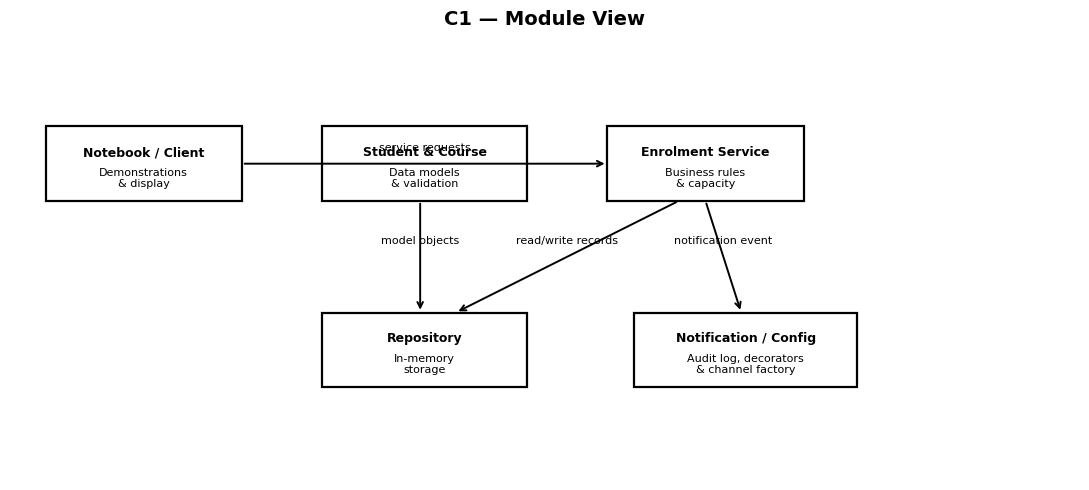

In [ ]:
boxes = [
    ("Notebook / Client", .4, 4.5, 2.2, 1.2, "Demonstrations\n& display"),
    ("Student & Course", 3.5, 4.5, 2.3, 1.2, "Data models\n& validation"),
    ("Enrolment Service", 6.7, 4.5, 2.2, 1.2, "Business rules\n& capacity"),
    ("Repository", 3.5, 1.5, 2.3, 1.2, "In-memory\nstorage"),
    ("Notification / Config", 7.0, 1.5, 2.5, 1.2, "Audit log, decorators\n& channel factory"),
]
arrows = [
    ((2.6,5.1),(6.7,5.1),"service requests"),
    ((7.5,4.5),(5.0,2.7),"read/write records"),
    ((7.8,4.5),(8.2,2.7),"notification event"),
    ((4.6,4.5),(4.6,2.7),"model objects"),
]
draw_architecture("C1 — Module View", boxes, arrows)

**Explanation:** The notebook client calls the application service rather than editing storage directly. The service coordinates student, course, and enrolment rules, while the repository owns the in-memory dictionaries. Notification and configuration responsibilities are separate from core data models. **Limitation/assumption:** The modules are represented as classes in one notebook rather than separate Python files.

### C2. Component-and-connector view

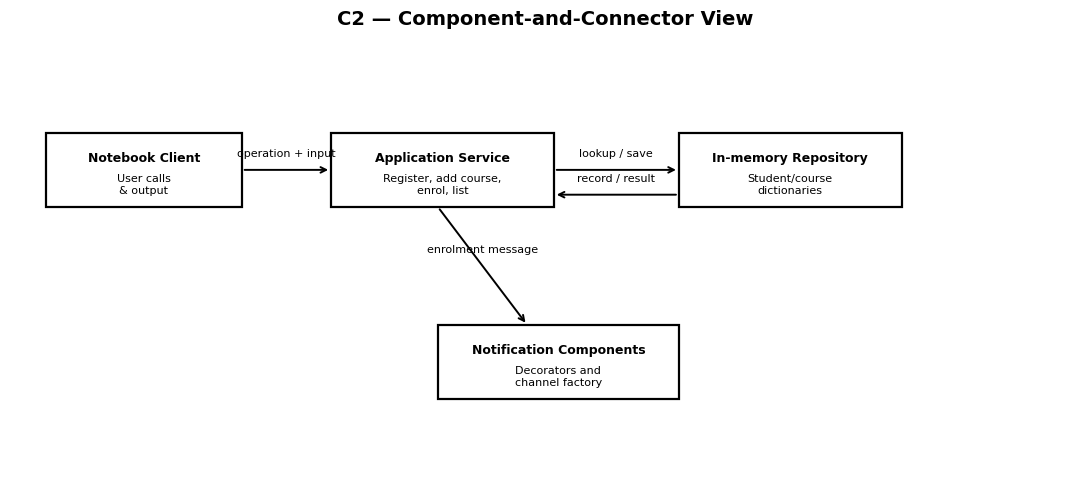

In [ ]:
boxes = [
    ("Notebook Client", .4, 4.4, 2.2, 1.2, "User calls\n& output"),
    ("Application Service", 3.6, 4.4, 2.5, 1.2, "Register, add course,\nenrol, list"),
    ("In-memory Repository", 7.5, 4.4, 2.5, 1.2, "Student/course\ndictionaries"),
    ("Notification Components", 4.8, 1.3, 2.7, 1.2, "Decorators and\nchannel factory"),
]
arrows = [
    ((2.6,5.0),(3.6,5.0),"operation + input"),
    ((6.1,5.0),(7.5,5.0),"lookup / save"),
    ((7.5,4.6),(6.1,4.6),"record / result"),
    ((4.8,4.4),(5.8,2.5),"enrolment message"),
]
draw_architecture("C2 — Component-and-Connector View", boxes, arrows)

**Explanation:** The notebook passes inputs to the application service. The service requests lookups and updates from the repository, which returns records or results. After successful enrolment, a message can be passed to notification components. **Limitation/assumption:** Connectors represent in-process Python method calls, not network connections.

### C3. Allocation view

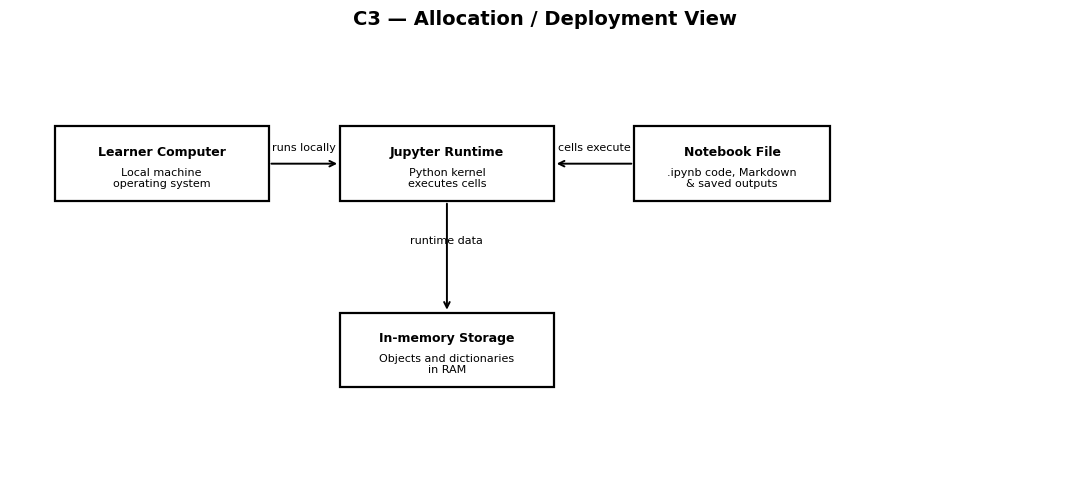

In [ ]:
boxes = [
    ("Learner Computer", .5, 4.5, 2.4, 1.2, "Local machine\noperating system"),
    ("Jupyter Runtime", 3.7, 4.5, 2.4, 1.2, "Python kernel\nexecutes cells"),
    ("Notebook File", 7.0, 4.5, 2.2, 1.2, ".ipynb code, Markdown\n& saved outputs"),
    ("In-memory Storage", 3.7, 1.5, 2.4, 1.2, "Objects and dictionaries\nin RAM"),
]
arrows = [
    ((2.9,5.1),(3.7,5.1),"runs locally"),
    ((7.0,5.1),(6.1,5.1),"cells execute"),
    ((4.9,4.5),(4.9,2.7),"runtime data"),
]
draw_architecture("C3 — Allocation / Deployment View", boxes, arrows)

**Explanation:** The learner opens the notebook locally in Jupyter. The Python kernel executes cells and holds application objects and dictionaries in RAM. The `.ipynb` file stores code, explanations, and saved outputs, but in-memory records are not persistent. **Limitation/assumption:** This is a local deployment; no remote database or server is used.

## Task D — Quality attributes and evaluation

### D1. Performance test

The following test measures time to create a collection of student records and search for one ID. Each size is tested five times and the median is reported. Results depend on machine specifications, Python version, and current system load.

,Input size (students),Repetitions,Median create + search time (ms)
0,100,5,0.133
1,1000,5,1.552
2,5000,5,11.065


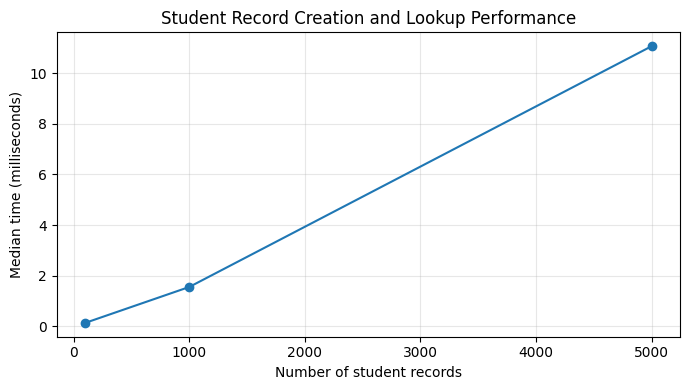

In [ ]:
def benchmark_student_lookup(size, repetitions=5):
    timings_ms = []
    target_id = f"STU{size-1:06d}"
    for _ in range(repetitions):
        start = perf_counter()
        records = {
            f"STU{i:06d}": Student(f"STU{i:06d}", f"Sample Student {i}")
            for i in range(size)
        }
        _ = records.get(target_id)
        timings_ms.append((perf_counter() - start) * 1000)
    return median(timings_ms)


sizes = [100, 1000, 5000]
benchmark_df = pd.DataFrame([
    {"Input size (students)": size, "Repetitions": 5,
     "Median create + search time (ms)": round(benchmark_student_lookup(size, 5), 3)}
    for size in sizes
])
display(benchmark_df)
plt.figure(figsize=(7,4))
plt.plot(benchmark_df["Input size (students)"],
         benchmark_df["Median create + search time (ms)"], marker="o")
plt.title("Student Record Creation and Lookup Performance")
plt.xlabel("Number of student records")
plt.ylabel("Median time (milliseconds)")
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

**Interpretation and limitations:** The table and plot measure local record construction plus one dictionary lookup. The timings include object creation, so they are not lookup-only results. Five repetitions and three sizes are an educational experiment, not proof of production scalability. Results vary with hardware, background tasks, Python version, and runtime conditions.

### D2. Reliability and defensive design — negative/edge-case tests

In [ ]:
def run_expected_error_test(label, action, expected_exception):
    try:
        action()
    except expected_exception as exc:
        return {"Test": label, "Result": "PASS", "Observed message": str(exc)}
    except Exception as exc:
        return {"Test": label, "Result": "FAIL",
                "Observed message": f"Wrong exception: {type(exc).__name__}: {exc}"}
    return {"Test": label, "Result": "FAIL", "Observed message": "No exception was raised"}


negative_service = StudentManagementService(InMemoryRepository())
negative_service.register_student("N001", "Lena Sample")
negative_service.register_student("N002", "Noah Sample")
negative_service.add_course("CAP01", "Capacity Test", 1)
negative_service.enrol_student("N001", "CAP01")
negative_results = [
    run_expected_error_test("Duplicate student ID",
        lambda: negative_service.register_student("N001", "Other Sample"), ValueError),
    run_expected_error_test("Unknown course",
        lambda: negative_service.enrol_student("N002", "MISSING"), LookupError),
    run_expected_error_test("Full course",
        lambda: negative_service.enrol_student("N002", "CAP01"), ValueError),
    run_expected_error_test("Invalid student input",
        lambda: negative_service.register_student("N003", ""), ValueError),
    run_expected_error_test("Unknown student",
        lambda: negative_service.enrol_student("MISSING", "CAP01"), LookupError),
]
negative_df = pd.DataFrame(negative_results)
display(negative_df)
assert (negative_df["Result"] == "PASS").all()
print("All negative/edge-case tests passed.")

,Test,Result,Observed message
0,Duplicate student ID,PASS,Student ID N001 already exists.
1,Unknown course,PASS,Course MISSING was not found.
2,Full course,PASS,Course CAP01 is full.
3,Invalid student input,PASS,Student name must contain at least two charact...
4,Unknown student,PASS,Student MISSING was not found.


All negative/edge-case tests passed.


### D3. Testability and maintainability — automated assertions

In [ ]:
test_service = StudentManagementService(InMemoryRepository())
student = test_service.register_student("T001", "Mira Example")
assert student.student_id == "T001"
assert len(test_service.list_students()) == 1

course = test_service.add_course("TST100", "Testing Basics", 1)
assert course.capacity == 1
assert test_service.enrol_student("T001", "TST100").startswith("Mira Example")
assert test_service.list_courses()[0]["enrolled"] == 1

try:
    test_service.register_student("T001", "Duplicate Example")
    raise AssertionError("Duplicate ID should have been rejected.")
except ValueError:
    pass

test_service.register_student("T002", "Nia Example")
try:
    test_service.enrol_student("T002", "TST100")
    raise AssertionError("Full course should have been rejected.")
except ValueError:
    pass

print("PASS: student registration")
print("PASS: course creation")
print("PASS: successful enrolment and enrolment count")
print("PASS: duplicate student rejected")
print("PASS: full course rejected")
print("All core assertions passed.")

PASS: student registration
PASS: course creation
PASS: successful enrolment and enrolment count
PASS: duplicate student rejected
PASS: full course rejected
All core assertions passed.


**Refactoring explanation:** A tangled design could combine input validation, storage updates, capacity checks, and printing in one large function. Here, validation belongs to model classes, storage belongs to `InMemoryRepository`, and use-case coordination belongs to `StudentManagementService`. This improves cohesion and reduces coupling because demonstration cells do not need to know how dictionaries are managed internally.

### D4. Quality trade-off reflection (150–200 words)

This prototype balances maintainability and flexibility against implementation simplicity and performance. Separating `Student`, `Course`, `InMemoryRepository`, and `StudentManagementService` makes the code easier to understand and test because each class has a focused responsibility. For example, course-capacity validation is handled by `Course.add_student`, while record retrieval is handled by the repository. This avoids repeating rules in multiple notebook cells and helps the negative tests check behaviour consistently. The trade-off is that a small educational system needs more classes and method calls than a single script with dictionaries and print statements. That extra structure introduces some complexity, but it makes future changes—such as replacing in-memory storage with a database repository—more manageable.

The performance experiment measures record creation and a dictionary lookup at 100, 1,000, and 5,000 records, using five repetitions and median timings. Dictionary lookup is generally efficient, but the recorded time also includes creating `Student` objects. Therefore, the results describe this local test rather than proving production scalability. In-memory storage is simple to start with, but it loses data when the kernel stops and does not provide multi-user access. For this prototype, maintainability and clear demonstration of architecture are prioritised over persistence and deployment complexity.

## Conclusion

The prototype demonstrates student management with separated responsibilities, input validation, three design patterns, three architecture views, and basic quality evaluation. The tests show how invalid operations are rejected, while the benchmark provides repeatable evidence about local performance. The main limitations are in-memory-only records, simulated notification channels, and environment-dependent timings. These are appropriate limitations for an educational prototype and identify clear areas for future development.